# EDA 
W tym notatniku przyjrzymy się bliżej `full_df.csv`, zlokalizujemy potencjalne problemy z danymi i przeprowadzimy wstępne analizy

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
from PIL import Image


Zacznijmy od przyjrzenia się strukturze df - typom kolumn rozmiarowi

In [45]:
df = pd.read_csv('data/full_df.csv')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6392 entries, 0 to 6391
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   ID                         6392 non-null   int64
 1   Patient Age                6392 non-null   int64
 2   Patient Sex                6392 non-null   str  
 3   Left-Fundus                6392 non-null   str  
 4   Right-Fundus               6392 non-null   str  
 5   Left-Diagnostic Keywords   6392 non-null   str  
 6   Right-Diagnostic Keywords  6392 non-null   str  
 7   N                          6392 non-null   int64
 8   D                          6392 non-null   int64
 9   G                          6392 non-null   int64
 10  C                          6392 non-null   int64
 11  A                          6392 non-null   int64
 12  H                          6392 non-null   int64
 13  M                          6392 non-null   int64
 14  O                          6392 non

In [5]:
df.head(5).T

,0,1,2,3,4
ID,0,1,2,4,5
Patient Age,69,57,42,53,50
Patient Sex,Female,Male,Male,Male,Female
Left-Fundus,0_left.jpg,1_left.jpg,2_left.jpg,4_left.jpg,5_left.jpg
Right-Fundus,0_right.jpg,1_right.jpg,2_right.jpg,4_right.jpg,5_right.jpg
Left-Diagnostic Keywords,cataract,normal fundus,laser spot，moderate non proliferative retinopathy,macular epiretinal membrane,moderate non proliferative retinopathy
Right-Diagnostic Keywords,normal fundus,normal fundus,moderate non proliferative retinopathy,mild nonproliferative retinopathy,moderate non proliferative retinopathy
N,0,1,0,0,0
D,0,0,1,1,1
G,0,0,0,0,0


In [6]:
df.isna().sum(axis = 0)

ID                           0
Patient Age                  0
Patient Sex                  0
Left-Fundus                  0
Right-Fundus                 0
Left-Diagnostic Keywords     0
Right-Diagnostic Keywords    0
N                            0
D                            0
G                            0
C                            0
A                            0
H                            0
M                            0
O                            0
filepath                     0
labels                       0
target                       0
filename                     0
dtype: int64

Nie ma żadnych `NaN` w zbiorze danych

In [7]:
print(f"Wymiar ramki danych: {df.shape}")

Wymiar ramki danych: (6392, 19)


In [8]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
ID,6392.0,2271.15,1417.56,0.0,920.75,2419.5,3294.0,4784.0
Patient Age,6392.0,57.86,11.73,1.0,51.00,59.0,66.0,91.0
N,6392.0,0.33,0.47,0.0,0.00,0.0,1.0,1.0
D,6392.0,0.33,0.47,0.0,0.00,0.0,1.0,1.0
G,6392.0,0.06,0.24,0.0,0.00,0.0,0.0,1.0
C,6392.0,0.06,0.24,0.0,0.00,0.0,0.0,1.0
A,6392.0,0.05,0.22,0.0,0.00,0.0,0.0,1.0
H,6392.0,0.03,0.18,0.0,0.00,0.0,0.0,1.0
M,6392.0,0.05,0.21,0.0,0.00,0.0,0.0,1.0
O,6392.0,0.25,0.43,0.0,0.00,0.0,0.0,1.0


Widać zatem, że:
- `ID` – unikalny identyfikator pacjenta (`int64`); jeden pacjent może mieć 1 lub 2 rekordy w tabeli.
- `Patient Age` – wiek pacjenta w latach (`int64`, zakres 1–91 lat, średnia ~58 lat; wymaga oczyszczenia anomalii wieku 1).
- `Patient Sex` – płeć pacjenta (`str`: 'Male' / 'Female').
- `Left-Fundus` – nazwa pliku bazowego ze zdjęciem dna lewego oka (`str`, np. `0_left.jpg`).
- `Right-Fundus` – nazwa pliku bazowego ze zdjęciem dna prawego oka (`str`, np. `0_right.jpg`).
- `Left-Diagnostic Keywords` – słowny opis diagnostyczny lekarza dla lewego oka (`str`).
- `Right-Diagnostic Keywords` – słowny opis diagnostyczny lekarza dla prawego oka (`str`).
- `N, D, G, C, A, H, M, O` – 8 flag binarnych (`int64`: 0 lub 1) sumarycznej diagnozy pacjenta:
  - `N` (*Normal*) – stan prawidłowy / zdrowe oko
  - `D` (*Diabetes*) – retinopatia cukrzycowa
  - `G` (*Glaucoma*) – jaskra
  - `C` (*Cataract*) – zaćma
  - `A` (*AMD*) – zwyrodnienie plamki żółtej
  - `H` (*Hypertension*) – retinopatia nadciśnieniowa
  - `M` (*Myopia*) – krótkowzroczność patologiczna
  - `O` (*Others*) – inne schorzenia
- `filepath` – archiwalna ścieżka do pliku obrazu w środowisku Kaggle (`str`).
- `labels` – właściwa klasa diagnostyczna przypisana do konkretnego zdjęcia w danym wierszu (`str`, np. `['N']`, `['C']`).
- `target` – reprezentacja One-Hot Encoding etykiety `labels` w postaci wektora 8-elementowego (`str`).
- `filename` – nazwa pliku obrazu z folderu `preprocessed_images`, do którego odnosi się dany wiersz (`str`, np. `0_right.jpg`).



In [9]:
# Sprawdzimy ile pacjentow ma 2 rekordy w bazie, a ile tylko 1
df_wynik = df.groupby("ID")["ID"].count().reset_index(name="Liczba wystąpień")
df_koncowy = df_wynik.groupby("Liczba wystąpień").size().reset_index(name="Ile takich ID")
print(df_koncowy)

   Liczba wystąpień  Ile takich ID
0                 1            324
1                 2           3034


N    33.0
D    33.0
G     6.0
C     6.0
A     5.0
H     3.0
M     5.0
O    25.0
dtype: float64

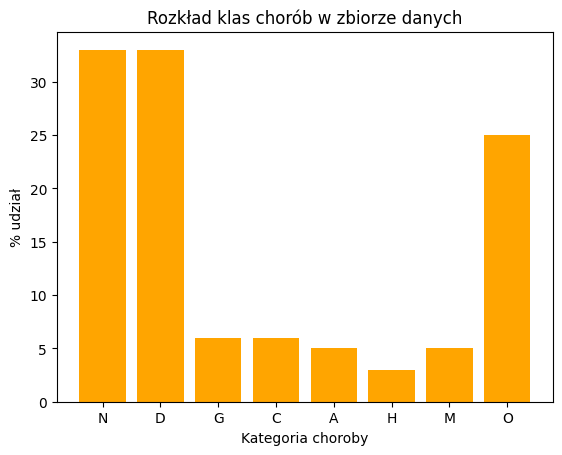

In [10]:
# Zbadamy rozkład klas chorób
cols = ['N', 'D', 'G','C', 'A', 'H', 'M', 'O']
distribution = df[cols].mean().round(2) * 100
display(distribution)

plt.bar(cols, distribution, color = 'orange')
plt.title("Rozkład klas chorób w zbiorze danych")
plt.xlabel("Kategoria choroby")
plt.ylabel("% udział")
plt.show()

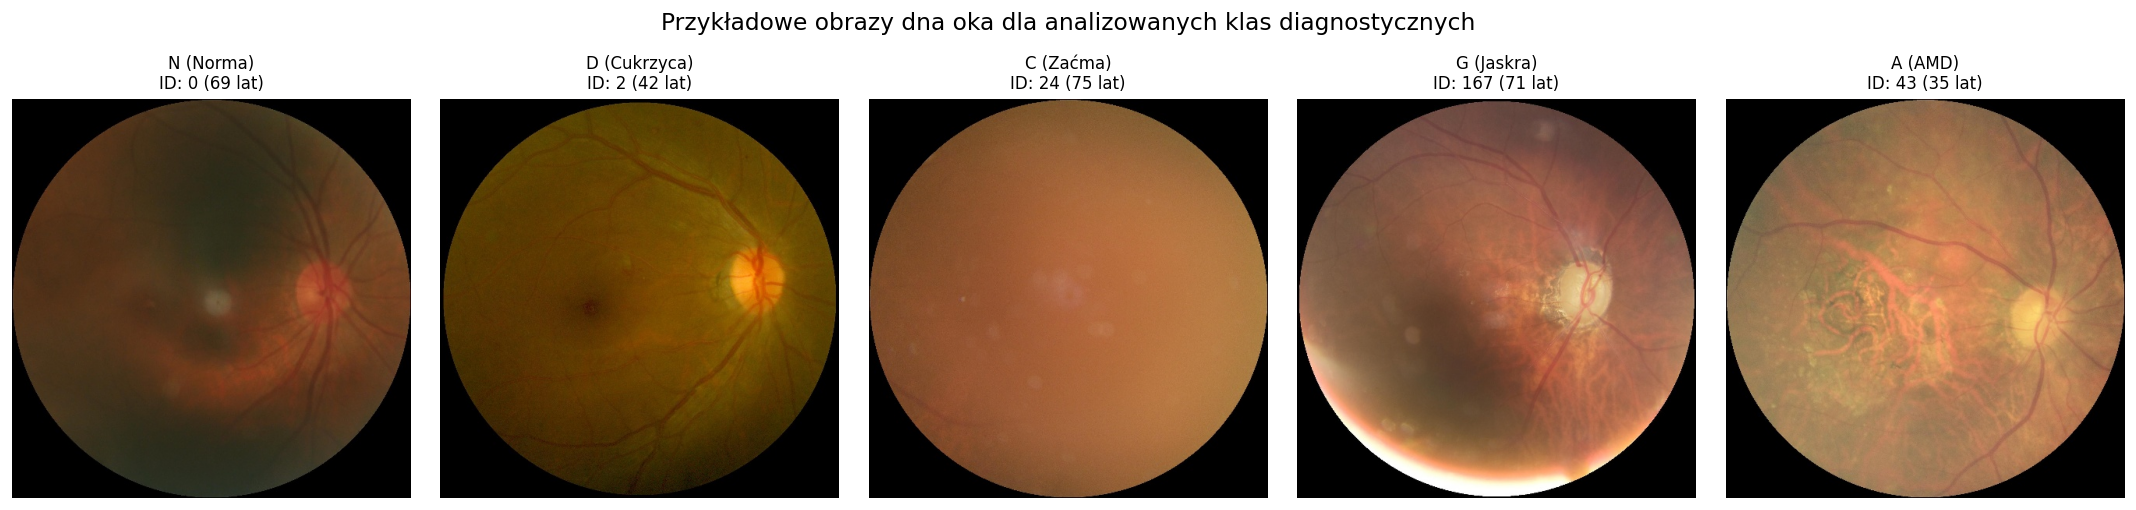

In [42]:
#Wyswietle po jednym przykladowym zdjeciu oka
classes_to_show = ["['N']", "['D']", "['C']", "['G']", "['A']"]
class_names = {
    "['N']": "N (Norma)",
    "['D']": "D (Cukrzyca)",
    "['C']": "C (Zaćma)",
    "['G']": "G (Jaskra)",
    "['A']": "A (AMD)"
}

fig, axes = plt.subplots(1, len(classes_to_show), figsize=(18, 4), dpi=120)

for i, cls in enumerate(classes_to_show):
    sample_row = df[df['labels'] == cls].iloc[0]
    img_path = os.path.join(IMAGE_DIR, sample_row['filename'])
    
    if os.path.exists(img_path):
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(f"{class_names[cls]}\nID: {sample_row['ID']} ({sample_row['Patient Age']} lat)", fontsize=10)
        axes[i].axis('off')
    else:
        axes[i].text(0.5, 0.5, "Brak pliku", ha='center')
        axes[i].axis('off')

plt.suptitle("Przykładowe obrazy dna oka dla analizowanych klas diagnostycznych", y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

Sprawdźmy jeszcze rozdzielczość i kompletność zdjęć

In [46]:
IMAGE_DIR = 'data/preprocessed_images'  

#sprawdzam czy wszystkie pliki z tabeli istnieją na dysku
df['file_exists'] = df['filename'].apply(lambda f: os.path.exists(os.path.join(IMAGE_DIR, f)))
missing_count = len(df) - df['file_exists'].sum()

print(f"Liczba zdjęć w tabeli: {len(df)}")
print(f"Liczba odnalezionych plików w folderze: {df['file_exists'].sum()}")
print(f"Brakujące pliki na dysku: {missing_count}")

#dla pewnosci sprawdzamy rozdzielczości losowych zdjec
sample_sizes = set()
for f in df['filename'].sample(50, random_state=42):
    path = os.path.join(IMAGE_DIR, f)
    if os.path.exists(path):
        with Image.open(path) as img:
            sample_sizes.add(img.size)

print(f"Rozdzielczości zdjęć w próbie (szerokość, wysokość): {sample_sizes}")

Liczba zdjęć w tabeli: 6392
Liczba odnalezionych plików w folderze: 6392
Brakujące pliki na dysku: 0
Rozdzielczości zdjęć w próbie (szerokość, wysokość): {(512, 512)}


---

### Krótka charakterystyka zbioru:
1. **Wymiary i kompletność:** 6392 wiersze i 19 kolumn; zbiór nie zawiera żadnych brakujących wartości (`NaN`).
2. **Jednostka obserwacji:** 1 wiersz reprezentuje pojedyncze oko (3194 prawych i 3198 lewych). Dane pochodzą od 3358 unikalnych pacjentów (3034 pacjentów posiada komplet obu oczu, a 324 tylko jedno oko).
3. **Niezbalansowanie klas:** Klasy są silnie niezbalansowane — dominują oczy zdrowe `N` oraz zmiany cukrzycowe `D` (ok 33%), podczas gdy pozostałe patologie stanowią po ok 5% zbioru. Wyjątek stanowi kategoria `O` która stanowi ok 25% zbiori
4. **Wymóg walidacji:** Ze względu na występowanie obu oczu tego samego pacjenta, podział na zbiór treningowy i testowy musi uwzględniać grupowanie po kolumnie `ID` (`StratifiedGroupKFold`), aby uniknąć *data leakage*.

Mamy 2 podejrzenia dotyczące zbioru danych: 
- Czy wiek `1` to rzeczywiscie wiek rocznego pacjenta, czy może sposob na uniknięcie `NaN`
- Czy pod kategorią `O` kryje się coś ciekawego

In [11]:
#Przyjrzyjmy się co kryje się pod klasą "O"
df_other = df.loc[df["labels"] == "['O']", :].copy()


#Poniewaz kazdy rekord odnosi się do jednego oka, to musze wyciagnac opis do stosownego oka
def get_eye_keyword(row):
    if 'left' in str(row['filename']).lower():
        return row['Left-Diagnostic Keywords']
    elif 'right' in str(row['filename']).lower():
        return row['Right-Diagnostic Keywords']
    return None

df_other["eye_keyword"] = df_other.apply(get_eye_keyword, axis = 1)

all_conditions = []
for k in df_other['eye_keyword'].dropna():
    parts = re.split(r'[,，;；]', str(k))
    for p in parts:
        cleaned = p.strip().lower()
        if cleaned:
            all_conditions.append(cleaned)

s_conditions = pd.Series(all_conditions).value_counts()
# Rozbijamy wielokrotne diagnozy w jednym oku (oddzielone przecinkami)
all_conditions = []
for k in df_other['eye_keyword'].dropna():
    parts = re.split(r'[,，;；]', str(k))
    for p in parts:
        cleaned = p.strip().lower()
        if cleaned:
            all_conditions.append(cleaned)

s_conditions = pd.Series(all_conditions).value_counts()

print("Top 15 najczęstszych przyczyn w kategorii 'Other' (na poziomie badanego oka):")
print(s_conditions.head(15))

Top 15 najczęstszych przyczyn w kategorii 'Other' (na poziomie badanego oka):
macular epiretinal membrane               167
drusen                                    160
epiretinal membrane                       135
myelinated nerve fibers                    77
vitreous degeneration                      61
refractive media opacity                   58
moderate non proliferative retinopathy     29
lens dust                                  27
maculopathy                                26
mild nonproliferative retinopathy          25
branch retinal vein occlusion              20
epiretinal membrane over the macula        12
laser spot                                  6
old branch retinal vein occlusion           5
pathological myopia                         4
Name: count, dtype: int64


Widać zatem że w kategorii other znajduje się spektrum schorzeń medycznych które, różnią się wyglądem miedzy sobą co moze powodowac gorsze uczenie sie sieci CNN. Co wiecej czesto niektore z tych kategorii jest skorelowane z innymi chorobami np cukrzyca.

Jako wniosek wszelkie klasyfikacje będziemy robić odfiltrowując klase "O", robiąc jedynie eksperymenty jak modele się zachowają kiedy dorzucimy kategorię "O" do uczneia.

Przyjrzyjmy sie jeszcze wiekowi pacjentów

<Axes: >

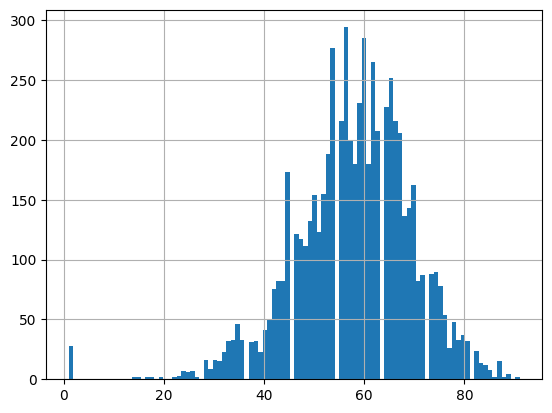

In [ ]:
df["Patient Age"].hist(bins=100)

Widać zatem że stosunkowo dużo osób ma wiek równy 1. Sprawdźmy czy to po prostu bardzo młodzi pacjenci, czy może jakiś sposób na zakodowanie `NaN`.

In [29]:
df.loc[df["Patient Age"] == 1, :].groupby("labels").size()

labels
['A']     2
['M']    24
['N']     2
dtype: int64

Zatem główną przyczyną choroby w wieku 1 roku jest krótkowzroczność patologiczna. Czy to jest choroba dzieci? 
Wśród pacjentów z wiekiem `1` znajduje się przypadek starczego zwyrodnienia plamki żółtej (`labels = ['A']`, opis: *dry age-related macular degeneration*). Diagnoza choroby starczej u rocznego dziecka jstoi w sprzeczności z wiekiem biologicznym.
Według wiedzy z internetu krótkowzroczność patologiczna rozwija się latami i nie występuje u noworodków, ze względu na to że dzieci rodzą się bardziej dalekowzroczne.   

W związku z tym wartość `1` traktujemy jako błąd wprowadzania danych. Przed modelowaniem wartości te zostaną zastąpione medianą wieku dla odpowiedniej klasy diagnostycznej (lub odfiltrowane na potrzeby modeli wykorzystujących cechy demograficzne).

### Zbadajmy korelacje między zmiennymi
Ponieważ w zbiorze danych wiekszość pacjentów wystepuje podwójnie (zarówno dla lewego i prawego oka), dlatego najpierw zrzuce duplikaty zeby rzetelnie zbadać korelacje pomiędzy zmiennymi.

In [ ]:
df_corr = df.drop_duplicates("ID")

<Axes: >

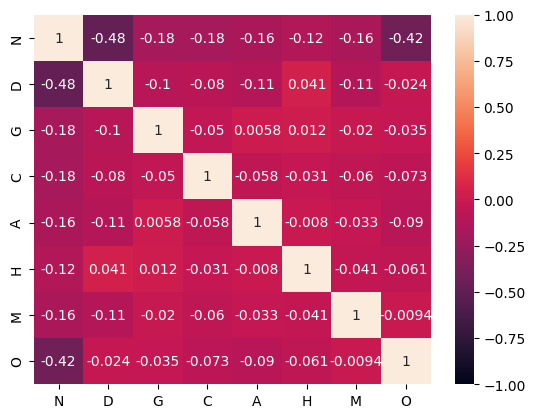

In [30]:
cols = ["N", "D", "G", "C", "A", "H", "M", "O"] #choroby ktore bede rozpatrywal
df_corr = df_corr[cols]

corr = df_corr.corr(method="pearson")
sns.heatmap(corr, vmin = -1, vmax=1, annot=True)

In [31]:
#Badanie symetrii diagnozy między lewym a prawym okiem
two_eyes_ids = df['ID'].value_counts()[df['ID'].value_counts() == 2].index #tylko id ktore wystapily 2 razy, cyzli rozpatruje pacjentow ktorzy mają zdjęcia obu oczu
df_two = df[df['ID'].isin(two_eyes_ids)]
left_diag = df_two[df_two['filename'].str.contains('left')].set_index('ID')['labels']
right_diag = df_two[df_two['filename'].str.contains('right')].set_index('ID')['labels']
eye_match = pd.DataFrame({'left': left_diag, 'right': right_diag}).dropna()
symmetry_pct = (eye_match['left'] == eye_match['right']).mean() * 100
print(f"\nProcent pacjentów z identyczną diagnozą w obu oczach: {symmetry_pct:.1f}%")


Procent pacjentów z identyczną diagnozą w obu oczach: 70.7%


C:\Users\48666\AppData\Local\Temp\ipykernel_31104\3745921014.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_plot_age, x='label_clean', y='Patient Age', order=order, palette='Set3', ax=axes[1])


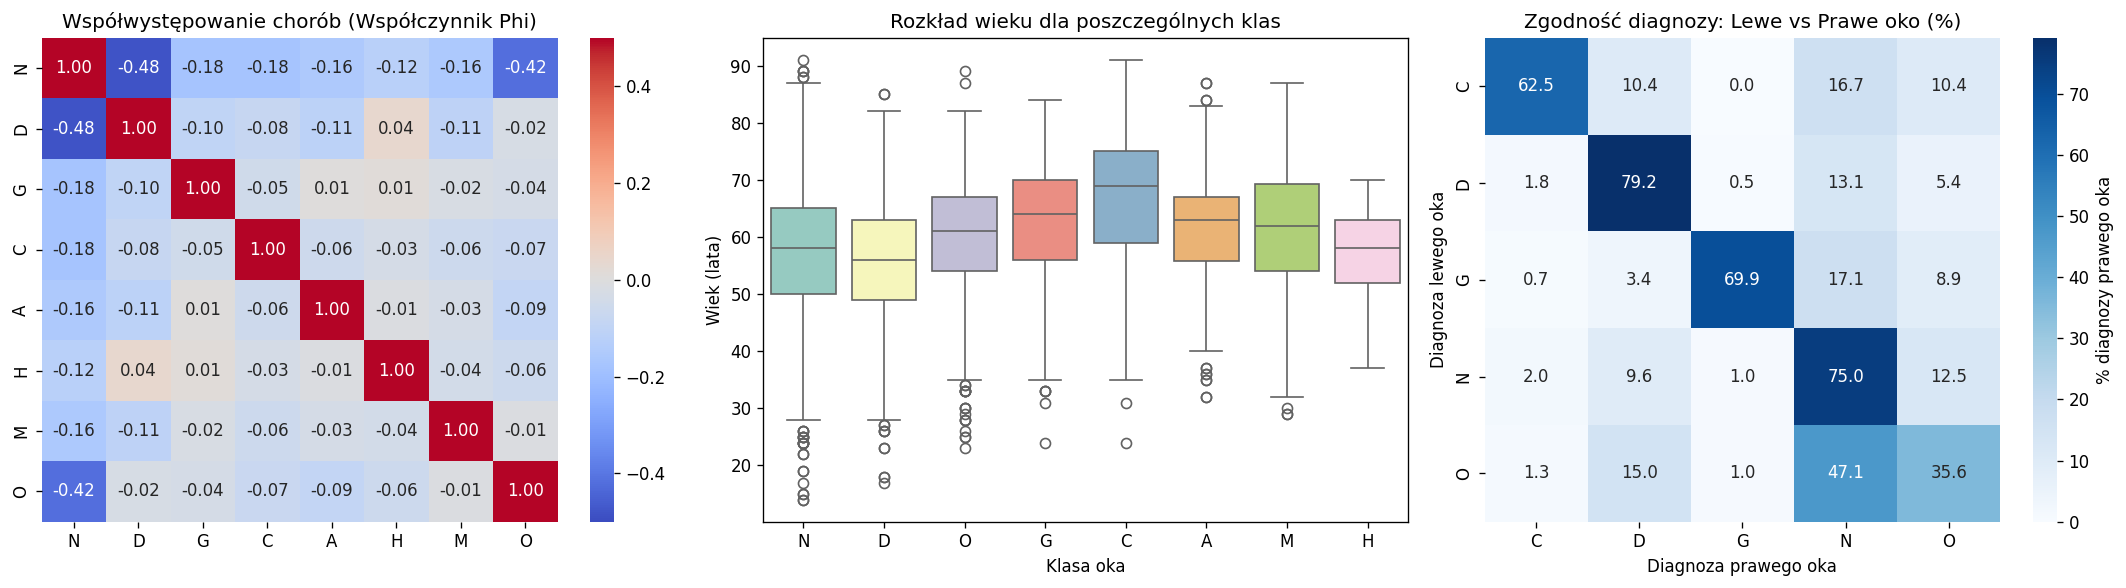

In [34]:
#Wizualizacja: Korelacje, Wiek i Asymetria oczu
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=120)

# Wykres 1: Macierz korelacji chorób
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.5, vmax=0.5, ax=axes[0])
axes[0].set_title('Współwystępowanie chorób (Współczynnik Phi)')

# Wykres 2: Rozkład wieku według klas (dla Age > 1)
df_plot_age = df[df['Patient Age'] > 1].copy()
df_plot_age['label_clean'] = df_plot_age['labels'].str.extract(r"\['([A-Z])'\]")
order = ['N', 'D', 'O', 'G', 'C', 'A', 'M', 'H']
sns.boxplot(data=df_plot_age, x='label_clean', y='Patient Age', order=order, palette='Set3', ax=axes[1])
axes[1].set_title('Rozkład wieku dla poszczególnych klas')
axes[1].set_xlabel('Klasa oka')
axes[1].set_ylabel('Wiek (lata)')

# Wykres 3: Macierz zgodności diagnozy Lewe vs Prawe oko
classes_top = ["['N']", "['D']", "['C']", "['G']", "['O']"]
sub_match = eye_match[eye_match['left'].isin(classes_top) & eye_match['right'].isin(classes_top)]
ct_matrix = pd.crosstab(sub_match['left'].str.replace(r"[\[\'\]]", "", regex=True),
                        sub_match['right'].str.replace(r"[\[\'\]]", "", regex=True), normalize='index') * 100
sns.heatmap(ct_matrix, annot=True, fmt='.1f', cmap='Blues', ax=axes[2], cbar_kws={'label': '% diagnozy prawego oka'})
axes[2].set_title('Zgodność diagnozy: Lewe vs Prawe oko (%)')
axes[2].set_xlabel('Diagnoza prawego oka')
axes[2].set_ylabel('Diagnoza lewego oka')

plt.tight_layout()
plt.show()

In [39]:
df_plot_age.groupby('labels')["Patient Age"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
labels,,,,,,,,
['A'],264.0,61.67,10.32,32.0,55.75,63.0,67.00,87.0
['C'],293.0,66.76,11.87,24.0,59.00,69.0,75.00,91.0
['D'],1608.0,55.70,10.20,17.0,49.00,56.0,63.00,85.0
['G'],284.0,63.02,10.93,24.0,56.00,64.0,70.00,84.0
['H'],128.0,57.05,7.52,37.0,52.00,58.0,63.00,70.0
['M'],208.0,61.11,10.92,29.0,54.00,62.0,69.25,87.0
['N'],2871.0,57.22,11.16,14.0,50.00,58.0,65.00,91.0
['O'],708.0,59.61,10.72,23.0,54.00,61.0,67.00,89.0


### Wnioski z analizy korelacji, rozkładu wieku i asymetrii oczu:

1. **Współwystępowanie schorzeń (Wykres 1):**
   - Flaga `N` (zdrowe dno oka) wykazuje silną ujemną korelację z cukrzycą `D` (-0.48) oraz kategorią `O` (-0.42)
   - Pomiędzy poszczególnymi patologiami korelacje są bliskie zeru z lekką dodatnią tendencją dla cukrzycy `D` i nadciśnienia `H`.

2. **Wiek pacjenta jako silny predyktor (Wykres 2):**
   - Rozkład wieku wyraźnie różnicuje jednostki chorobowe:
     * **Zaćma (`C`):** Schorzenie pacjentów w podeszłym wieku – mediana wynosi aż **69 lat** (z wyraźnym przesunięciem całego pudełka w górę).
     * **Jaskra (`G`) i AMD (`A`):** Mediana wieku wynosi odpowiednio **64 i 63 lata**.
     * **Cukrzyca (`D`):** Wyraźnie młodsza grupa pacjentów (mediana **56 lat**).
   - Wniosek: Wiek (`Patient Age`) będzie niósł  wysoką wagę informacyjną w modelach wielomodalnych i klasycznym ML.

3. **Asymetria kliniczna między lewym a prawym okiem (Wykres 3):**
   - W **70.7%** przypadków oboje oczu pacjenta ma identyczną diagnozę.
   - W **29.3%** przypadków występuje asymetria (np. jedno oko jest zdrowe `N`, a drugie ma zaćmę `C`, cukrzycę `D` lub jaskrę `G`).
---

## Podsumowanie EDA i decyzje do Preprocessingu / Modelowania:

1. **Ochrona przed przeciekiem danych (Data Leakage):**
   Podział danych na zbiór treningowy i walidacyjny/testowy musi bezwzględnie opierać się na `StratifiedGroupKFold` z grupowaniem po kolumnie `ID` pacjenta, aby zdjęcia lewego i prawego oka tej samej osoby nigdy nie trafiły do różnych podzbiorów.
2. **Czyszczenie anomalii wieku:**
   Wartość `Patient Age == 1` uznaje za szpitalny kod braku danych i przed trenowaniem modeli zastąpie je medianą wieku dla odpowiedniej klasy diagnostycznej.
3. **Selekcja klas do eksperymentów:**
   Odrzucam kategorię `"O"`, w procesie trenowania modeli.
